# Siting a 100 MW Data Center: an Interconnection Screening Study

**The request.** A developer wants to connect a 100 MW data center to the
transmission system and has options at six substations. The utility has to
answer three questions before it can make an offer:

1. **Where** should it connect?
2. **What does it cost the system** to serve it there?
3. **What has to be built** so that the system still meets its reliability
   criteria with the new load in place?

The answer is not simply the site with the lowest price. A site can be cheap
to serve on a normal day and still leave the system unable to survive the
loss of a line or a generating unit. An interconnection study therefore weighs
cost against **reliability under contingencies** and against **the network
upgrades needed to restore it**. This notebook works through that study on
the WSCC 9-bus test system, in the stages a planning engineer would follow:

| stage | question | method |
|---|---|---|
| 0 | what is already wrong with the system? | base-case AC-OPF and N-1 scan |
| 1 | which sites look cheapest? | nodal prices from **one** AC-OPF |
| 2 | what does each site actually cost? | AC-OPF re-solved with the load at each site |
| 3 | does the system survive N-1 at each site? | line outages (no redispatch) and unit outages (with redispatch) |
| 4 | what upgrades would fix the finalists? | sizing by sensitivity, verified by re-solving |
| 5 | how much room is left to grow? | hosting capacity, without and with N-1 |
| 6 | does the answer hold with load growth? | the same scan at +10 % load |

It ends with a scorecard and a recommendation.

## Study basis and assumptions

Every interconnection study begins by stating its basis, because the answer is
only as good as the case it was run on.

| item | assumption |
|---|---|
| system | WSCC 9-bus (MATPOWER `case9`): 3 units, 6 transmission lines, 3 generator step-up branches, 315 MW of load, all at 345 kV |
| planning case | load as published; a **+10 % load-growth** case as a sensitivity |
| new load | 100 MW at 0.98 power factor lagging (20.3 MVAr), constant power: a data center draws near-constant power through its UPS and power supplies |
| candidate sites | the six transmission substations, buses 4 to 9. Buses 1 to 3 are generator terminals; co-locating a load behind a plant's meter raises separate regulatory and operating questions and is out of scope here |
| dispatch | security-unconstrained AC optimal power flow (`dp.solve_acopf`) |
| thermal limits | each branch's single rating in the case file, used as both the normal and the emergency rating |
| voltage limits | 0.90 to 1.10 pu, normal and post-contingency |
| contingencies | single outages (N-1) in the spirit of NERC TPL-001 category P1: each of the 6 lines, and each of the 2 non-slack units with the step-up branch that connects it |
| post-contingency state, line outage | AC power flow with the pre-contingency dispatch and generator voltage setpoints held; the slack unit absorbs the change in losses. This is the instantaneous state before operators act |
| post-contingency state, unit outage | AC-OPF re-dispatch of the remaining units: losing a unit is covered by reserves, and the test is whether a dispatch inside every limit exists |
| attribution | a violation counts against the project only if it is **new**, or an existing one **worsened** by more than 1 % of rating or 0.01 pu |

What this study does **not** cover, and a full system impact study would:
short-circuit duty, transient and voltage stability, N-1-1 and breaker-failure
events, protection, and production-cost simulation over the hours of a year.
It is a screening study: its job is to choose where to look closely.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)

from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np

import difflow_power as dp
from difflow_power.network import Load
from difflow_power.residuals import power_state_layout

PROJECT_MW = 100.0
POWER_FACTOR = 0.98
CANDIDATES = ["4", "5", "6", "7", "8", "9"]
LINES = ["br2", "br3", "br5", "br6", "br8", "br9"]     # the six network lines
UNITS = ["g2", "g3"]                                   # g1 is the slack unit
TOL = 0.01                                             # attribution threshold

case = dp.cases.case9()
print(case.summary())


def label(net, branch):
    br = net.branches[branch]
    return f"{br.from_bus}-{br.to_bus}"


for b in LINES:
    br = case.branches[b]
    print(f"  line {label(case, b):4s} rating {br.rate_mva:5.0f} MVA")

case9 (WSCC 9-bus): 9 buses (1 slack, 2 PV, 6 PQ), 9 branches (0 transformers, 9 rated), 3 generators (820 MW capacity), 3 loads (315.0 MW + 115.0 MVAr), 1 loops, base 100 MVA
  line 4-5  rating   250 MVA
  line 5-6  rating   150 MVA
  line 6-7  rating   150 MVA
  line 7-8  rating   250 MVA
  line 8-9  rating   250 MVA
  line 9-4  rating   250 MVA


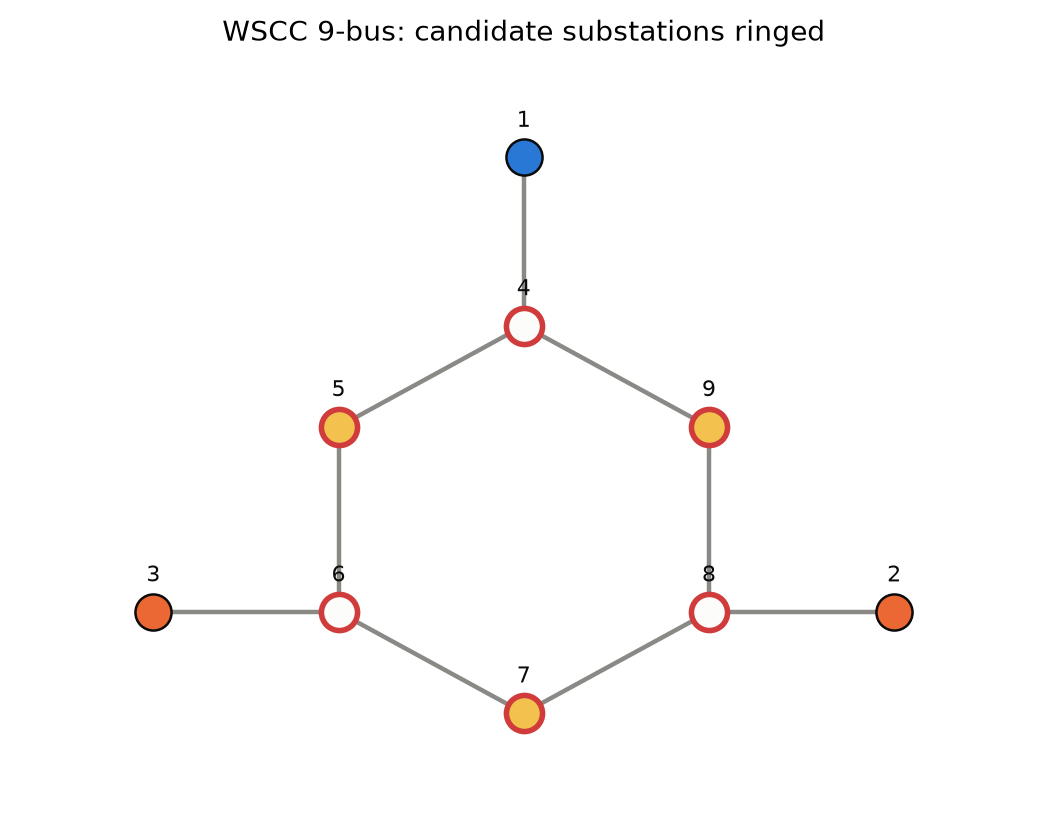

In [2]:
POS = {"1": (0.0, 2.1), "4": (0.0, 1.1), "5": (-1.1, 0.5), "9": (1.1, 0.5),
       "6": (-1.1, -0.6), "8": (1.1, -0.6), "7": (0.0, -1.2),
       "3": (-2.2, -0.6), "2": (2.2, -0.6)}
fig, ax = plt.subplots(figsize=(6.5, 5))
dp.draw_network(case, pos=POS, highlight=CANDIDATES, ax=ax,
                title="WSCC 9-bus: candidate substations ringed")
plt.show()

### Tools for the study

Four small functions do all the work. `with_load` attaches the data center;
`contingency_scan` runs every N-1 event and returns each limit it breaks, as a
record keyed by `(event, element)`; `attributable` compares a scan against the
pre-project scan and keeps only what the project caused or worsened.

In [3]:
def with_load(net, bus, mw=PROJECT_MW):
    loads = dict(net.loads)
    loads["dc"] = Load(bus=bus, p_mw=mw,
                       q_mvar=mw * np.tan(np.arccos(POWER_FACTOR)),
                       name="data center")
    return replace(net, loads=loads)


def with_capacitor(net, bus, mvar):
    buses = dict(net.buses)
    buses[bus] = replace(buses[bus], b_shunt_mvar=buses[bus].b_shunt_mvar + mvar)
    return replace(net, buses=buses)


def line_outage_case(net, opf, line):
    # Pre-contingency dispatch and voltage setpoints held; the line removed.
    gens = {g: replace(u, p_mw=opf.pg_mw[g]) for g, u in net.generators.items()}
    buses = {b: replace(x, vm_setpoint=opf.vm[b]) for b, x in net.buses.items()}
    branches = {a: x for a, x in net.branches.items() if a != line}
    return replace(net, branches=branches, generators=gens, buses=buses)


def unit_outage_case(net, unit):
    bus = net.generators[unit].bus
    gens = {g: u for g, u in net.generators.items() if g != unit}
    buses = {b: (replace(x, kind="pq") if b == bus else x)
             for b, x in net.buses.items()}
    return replace(net, generators=gens, buses=buses)


def contingency_scan(net, opf):
    # Returns {(event, element): {"excess": ..., "text": ...}}.
    out = {}
    for line in LINES:
        event = f"loss of line {label(net, line)}"
        post = line_outage_case(net, opf, line)
        pf = dp.solve_power_flow(post)
        if not pf.converged:
            out[(event, "solution")] = dict(
                excess=np.inf, text="no power-flow solution (voltage collapse?)")
            continue
        rep = dp.operating_report(pf.x, post)
        for br, loading in rep.thermal_violations.items():
            out[(event, br)] = dict(
                excess=loading - 1.0,
                text=f"line {label(net, br)} at {100 * loading:.0f} % of rating")
        for bus, dv in rep.voltage_violations.items():
            out[(event, f"bus {bus}")] = dict(
                excess=abs(dv), text=f"bus {bus} at {pf.vm[bus]:.3f} pu")
    for unit in UNITS:
        event = f"loss of unit {unit[1:]}"
        post = unit_outage_case(net, unit)
        res = dp.solve_acopf(post)
        if not (res.converged and dp.operating_report(res.x, post).feasible):
            out[(event, "redispatch")] = dict(
                excess=np.inf, text="no feasible redispatch found")
    return out


def attributable(before, after, tol=TOL):
    return {k: v for k, v in after.items()
            if k not in before or v["excess"] > before[k]["excess"] + tol}


def show(records, indent="  "):
    if not records:
        print(indent + "none")
    for (event, _), r in sorted(records.items()):
        print(f"{indent}{event:22s} {r['text']}")

## Stage 0: the system before the project

Run the base case first. Two things come out of it: the pre-project cost and
prices that the screen will use, and the list of N-1 problems that **already
exist**. A study that skipped this step would charge the project for problems
it did not cause.

In [4]:
base_opf = dp.solve_acopf(case)
print(base_opf.summary())
base_scan = contingency_scan(case, base_opf)
print("\nN-1 violations that exist BEFORE the project:")
show(base_scan)

case9 (WSCC 9-bus): converged in 19 interior-point iterations, cost $5296.69/h for 315.0 MW load (3.31 MW loss); LMP 24.03 to 25.00 $/MWh; 3 binding constraints (vm_1_max, vm_6_max, vm_8_max)



N-1 violations that exist BEFORE the project:
  loss of line 8-9       bus 9 at 0.896 pu
  loss of line 9-4       bus 9 at 0.791 pu


The test system is not N-1 secure as published. Bus 9 serves 125 MW, the
largest load, through two lines. Lose line 9-4 and it hangs on the long 8-9
line alone, dropping to about 0.79 pu; lose 8-9 and it sits just under the
0.90 pu limit. That is an existing deficiency for the
utility to fix, not something the data center caused. It is recorded here so
the project is not charged with it, and every later scan is compared against
this list.

## Stage 1: screen every site from one solve

The nodal price at a bus is the marginal cost of serving load there. Price
times 100 MW is therefore a first-order estimate of what the project adds to
system cost, and it comes from the base solve already in hand: one solve for
all six sites, or for six hundred.

In [5]:
lmp = base_opf.lmp_mw
screen = {b: lmp[b] * PROJECT_MW for b in CANDIDATES}
print(f"{'site':>5} {'LMP $/MWh':>10} {'est. $/h':>9}")
for b in sorted(CANDIDATES, key=screen.get):
    print(f"{'bus ' + b:>5} {lmp[b]:10.2f} {screen[b]:9.0f}")

 site  LMP $/MWh  est. $/h
bus 8      24.03      2403
bus 6      24.08      2408
bus 7      24.25      2425
bus 4      24.76      2476
bus 5      25.00      2500
bus 9      25.00      2500


The prices span only about 4 %, because nothing is congested in the base case:
the spread is losses. On cost alone the screen points at buses 8 and 6 and
away from 5 and 9.

## Stage 2: re-solve with the project at each site

100 MW is a third of the system load, not a marginal increment, so each site is
re-solved with the load in place. The re-solve also reports what the screen
cannot: the change in losses, the lowest voltage and the limits that bind.

In [6]:
site_opf = {}
print(f"{'site':>5} {'screen $/h':>10} {'re-solve $/h':>12} {'gap':>6} "
      f"{'d losses MW':>11} {'min V pu':>8}  binding")
for b in sorted(CANDIDATES, key=screen.get):
    net = with_load(case, b)
    res = dp.solve_acopf(net)
    assert res.converged and dp.operating_report(res.x, net).feasible
    site_opf[b] = res
    d_cost = res.cost - base_opf.cost
    bind = [k for k in res.binding() if not k.startswith("vm_")]
    print(f"{'bus ' + b:>5} {screen[b]:10.0f} {d_cost:12.0f} "
          f"{100 * (d_cost / screen[b] - 1):5.1f}% "
          f"{res.losses_mw - base_opf.losses_mw:11.2f} "
          f"{min(res.vm.values()):8.3f}  {', '.join(bind) or '-'}")

d_cost = {b: site_opf[b].cost - base_opf.cost for b in CANDIDATES}

 site screen $/h re-solve $/h    gap d losses MW min V pu  binding


bus 8       2403         2756  14.7%       -0.50    1.070  -


bus 6       2408         2769  15.0%       -0.09    1.073  -


bus 7       2425         2793  15.1%        0.68    1.070  -


bus 4       2476         2865  15.7%        2.83    1.058  -


bus 5       2500         2919  16.7%        4.60    1.047  -


bus 9       2500         2912  16.5%        4.39    1.033  -


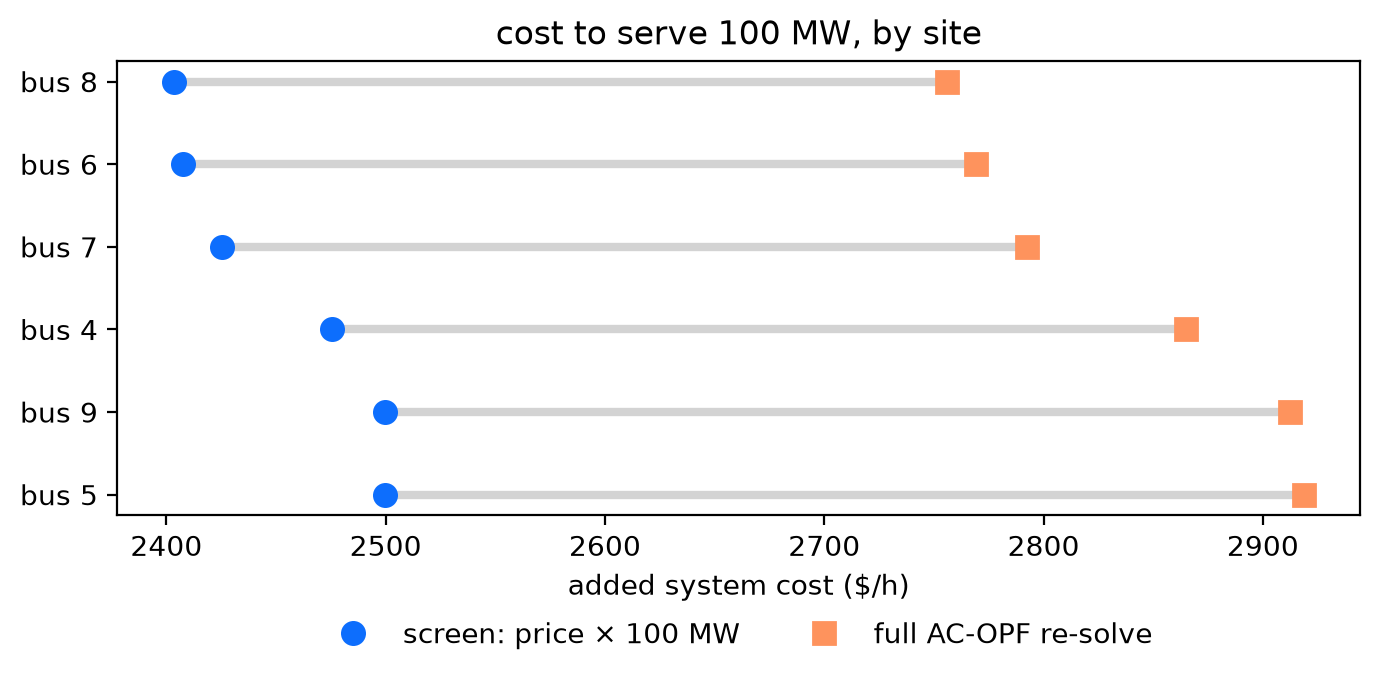

In [7]:
order = sorted(CANDIDATES, key=d_cost.get)
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hlines(y, [screen[b] for b in order], [d_cost[b] for b in order],
          color="lightgrey", lw=3, zorder=1)
ax.plot([screen[b] for b in order], y, "o", ms=8, label="screen: price × 100 MW")
ax.plot([d_cost[b] for b in order], y, "s", ms=8, label="full AC-OPF re-solve")
ax.set_yticks(y, [f"bus {b}" for b in order])
ax.invert_yaxis()
ax.set_xlabel("added system cost ($/h)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
ax.set_title("cost to serve 100 MW, by site")
plt.tight_layout()
plt.show()

The screen ranks the six sites in the same order as six full re-solves, except
for buses 5 and 9: both price at 25.00 $/MWh, so the screen cannot separate
them, and re-solved they differ by $7/h. It underestimates each site by 15 to
17 %. The gap is the curvature of the cost curves over 100 MW, and it is
nearly the same at every site, which is why the **ranking** survives. That is what a screen is for: the cheap solve picks the
short list and the expensive ones confirm it. Sites 6 and 8 also *reduce*
losses, because they take load closer to the units at buses 3 and 2.

Every site is feasible with all lines in service. On cost alone this would be
a choice between buses 8 and 6, about $13/h apart. N-0 is not the criterion,
though.

## Stage 3: N-1 at each site

Run every contingency with the data center at each site and keep only what the
project caused or worsened.

In [8]:
site_scan, site_new = {}, {}
for b in order:
    site_scan[b] = contingency_scan(with_load(case, b), site_opf[b])
    site_new[b] = attributable(base_scan, site_scan[b])
    print(f"bus {b}  (+{d_cost[b]:.0f} $/h): "
          f"{len(site_new[b])} project-attributable violations")
    show(site_new[b], indent="    ")

bus 8  (+2756 $/h): 3 project-attributable violations
    loss of line 9-4       line 6-7 at 111 % of rating
    loss of line 9-4       bus 9 at 0.748 pu
    loss of unit 2         no feasible redispatch found


bus 6  (+2769 $/h): 1 project-attributable violations
    loss of line 4-5       bus 5 at 0.882 pu


bus 7  (+2793 $/h): 7 project-attributable violations
    loss of line 4-5       bus 5 at 0.893 pu
    loss of line 6-7       bus 7 at 0.861 pu
    loss of line 7-8       line 6-7 at 156 % of rating
    loss of line 7-8       bus 7 at 0.791 pu
    loss of line 9-4       line 6-7 at 112 % of rating
    loss of line 9-4       bus 9 at 0.759 pu
    loss of unit 2         no feasible redispatch found


bus 4  (+2865 $/h): 5 project-attributable violations
    loss of line 5-6       bus 5 at 0.889 pu
    loss of line 5-6       bus 9 at 0.887 pu
    loss of line 8-9       line 5-6 at 129 % of rating
    loss of line 8-9       bus 5 at 0.891 pu
    loss of line 8-9       bus 9 at 0.855 pu


bus 9  (+2912 $/h): 10 project-attributable violations
    loss of line 5-6       bus 5 at 0.892 pu
    loss of line 5-6       bus 9 at 0.865 pu
    loss of line 7-8       bus 9 at 0.894 pu
    loss of line 8-9       line 1-4 at 107 % of rating
    loss of line 8-9       line 5-6 at 132 % of rating
    loss of line 8-9       line 9-4 at 111 % of rating
    loss of line 8-9       bus 4 at 0.876 pu
    loss of line 8-9       bus 5 at 0.855 pu
    loss of line 8-9       bus 9 at 0.732 pu
    loss of line 9-4       no power-flow solution (voltage collapse?)


bus 5  (+2919 $/h): 6 project-attributable violations
    loss of line 4-5       no power-flow solution (voltage collapse?)
    loss of line 5-6       bus 5 at 0.785 pu
    loss of line 5-6       bus 9 at 0.862 pu
    loss of line 8-9       line 5-6 at 131 % of rating
    loss of line 8-9       bus 5 at 0.869 pu
    loss of line 8-9       bus 9 at 0.865 pu


In [9]:
def tally(records):
    thermal = sum(1 for (e, k), r in records.items() if k.startswith("br"))
    voltage = sum(1 for (e, k), r in records.items() if k.startswith("bus"))
    severe = sum(1 for r in records.values() if np.isinf(r["excess"]))
    return thermal, voltage, severe

print(f"{'site':>5} {'+$/h':>6} {'thermal':>8} {'voltage':>8} {'no solution':>12}")
for b in order:
    t, v, s = tally(site_new[b])
    print(f"{'bus ' + b:>5} {d_cost[b]:6.0f} {t:8d} {v:8d} {s:12d}")

 site   +$/h  thermal  voltage  no solution
bus 8   2756        1        1            1
bus 6   2769        0        1            0
bus 7   2793        2        4            1
bus 4   2865        1        4            0
bus 9   2912        3        6            1
bus 5   2919        1        4            1


This is where the decision is made, and the cost ranking does not survive it.

- **Bus 6** causes a single problem: after the loss of line 4-5, bus 5 sags
  to 0.882 pu, just below the 0.90 pu limit. It survives both unit outages,
  and it worsens no existing problem past the attribution threshold.
- **Bus 8**, the cheapest site, overloads line 6-7 to 111 % after the loss
  of 9-4 and deepens the existing bus 9 sag on that outage to 0.75 pu. Worse,
  after the loss of unit 2 (its neighbour), no redispatch of the remaining
  units was found that serves the system within limits: the power has to come
  from units 1 and 3 through lines that are already full.
- **Bus 7** fails the same unit outage and overloads line 6-7 to 156 % after
  the loss of 7-8.
- **Buses 4, 5 and 9** are the three most expensive sites, and each causes
  five or more violations. Buses 5 and 9 each leave an outage with no
  power-flow solution at all, the signature of voltage collapse; bus 4
  overloads line 5-6 to 129 % after the loss of 8-9.

The cheapest site is not the most reliable one. Buses 6 and 8 go forward as
finalists: 6 because its single problem looks easy to fix, 8 because it is
the cheapest.

## Stage 4: what would fix the finalists?

### Bus 6: reactive support at bus 5

A voltage sag after a contingency is a reactive-power problem, and the standard
fix is a shunt capacitor bank. Size it from the post-contingency sensitivity
`dV₅/dQ₅`, which `dp.demand_sensitivity` takes directly from the solved power
flow by the implicit function theorem. That is one linear solve, not a sweep
of trial bank sizes.

A bank's output falls with the square of the voltage (`Q = B V²`), and the OPF
re-dispatches around it, so the linear estimate is a first Newton step. Take
another from the new point, then round up to a standard bank size.

In [10]:
def post_contingency_voltage(net, bus, line):
    # Post-contingency voltage at `bus`, and dV/dQ there (pu per MVAr).
    opf = dp.solve_acopf(net)
    post = line_outage_case(net, opf, line)
    pf = dp.solve_power_flow(post)
    layout = power_state_layout(post)
    dv_dqload = dp.demand_sensitivity(post, reactive=True)[
        layout.index(f"vm_{bus}"), post.bus_index[bus]]
    # injecting Q is negative load; per MVAr rather than per pu
    return pf.vm[bus], -float(dv_dqload) / post.base_mva


def size_bank(build, bus, line, target=0.90):
    # Newton on the bank rating; build(mvar) returns the network with it.
    cap = 0.0
    for _ in range(4):
        v, slope = post_contingency_voltage(build(cap), bus, line)
        print(f"  bank {cap:5.1f} MVAr: post-contingency V{bus} = {v:.4f} pu, "
              f"dV/dQ = {1000 * slope:.2f} mpu per MVAr")
        if v >= target:
            break
        # the bank delivers B V^2, so rated MVAr = needed injection / V^2
        cap += (target - v) / slope / v**2
    return cap


cap = size_bank(lambda q: with_capacitor(with_load(case, "6"), "5", q),
                bus="5", line="br2")
BANK = 5.0 * np.ceil(cap / 5.0)
print(f"\nNewton estimate {cap:.1f} MVAr -> specify a {BANK:.0f} MVAr bank")

  bank   0.0 MVAr: post-contingency V5 = 0.8816 pu, dV/dQ = 3.07 mpu per MVAr


  bank   7.7 MVAr: post-contingency V5 = 0.9003 pu, dV/dQ = 3.04 mpu per MVAr

Newton estimate 7.7 MVAr -> specify a 10 MVAr bank


In [11]:
net6 = with_capacitor(with_load(case, "6"), "5", BANK)
opf6 = dp.solve_acopf(net6)
scan6 = contingency_scan(net6, opf6)
print(f"bus 6 + {BANK:.0f} MVAr at bus 5: cost +{opf6.cost - base_opf.cost:.0f} $/h,"
      f" N-0 feasible: {dp.operating_report(opf6.x, net6).feasible}")
print("project-attributable N-1 violations:")
show(attributable(base_scan, scan6))

bus 6 + 10 MVAr at bus 5: cost +2769 $/h, N-0 feasible: True
project-attributable N-1 violations:
  none


One small capacitor bank at an existing substation clears every violation the
project causes at bus 6, and the system cost barely moves.

### Bus 8: what the problems need

Bus 8's problems are not reactive. The line 6-7 overload is a thermal limit,
and the failed redispatch after losing unit 2 is a deliverability limit: there
is not enough transfer capability to bring replacement power to the east side
of the system. Each needs new or rebuilt transmission.

In [12]:
for (event, element), r in sorted(site_new["8"].items()):
    if element.startswith("br"):
        br = case.branches[element]
        need = (1.0 + r["excess"]) * br.rate_mva
        print(f"{event}: line {label(case, element)} must carry {need:.0f} MVA "
              f"against a {br.rate_mva:.0f} MVA rating "
              f"(+{need - br.rate_mva:.0f} MVA)")

post = unit_outage_case(with_load(case, "8"), "g2")
res = dp.solve_acopf(post)
print(f"\nloss of unit 2 with the project at bus 8: converged={res.converged};"
      f" limits holding the last iterate: "
      f"{sorted(k for k in res.binding() if not k.startswith('vm_'))}")

loss of line 9-4: line 6-7 must carry 167 MVA against a 150 MVA rating (+17 MVA)



loss of unit 2 with the project at bus 8: converged=False; limits holding the last iterate: ['rate_from_0', 'rate_from_4']


After unit 2 is lost, the last interior-point iterate is pinned against unit
1's maximum output and the ratings of its step-up branch (`rate_from_0`, branch
1-4) and of line 6-7 (`rate_from_4`). Replacing unit 2's output needs more
transfer capability out of units 1 and 3: a reconductored or new line, not a
capacitor bank. "No feasible redispatch found" is not a proof that none
exists, so a full study would confirm it with a security-constrained OPF. As a
screening result, it puts bus 8 well behind bus 6.

## Stage 5: room to grow

Data centers are built in phases, so it matters how much more the site could
take. Two capacities answer different questions:

- **N-0 hosting capacity**: the largest load the AC-OPF can serve within every
  limit with everything in service.
- **N-1 hosting capacity**: the largest load that causes **no**
  project-attributable N-1 violation. This is the one that decides what can
  connect without upgrades.

Both come from bisection on the load. Each step is a full AC-OPF (and, for N-1,
the contingency scan). "Feasible" means the solver found a dispatch inside
every limit, so these are capacities **found**, to within the bisection
tolerance.

In [13]:
def bisect(ok, lo, hi, steps=6):
    if ok(hi):
        return hi
    for _ in range(steps):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if ok(mid) else (lo, mid)
    return lo


def n0_ok(site, mw):
    net = with_load(case, site, mw)
    res = dp.solve_acopf(net)
    return res.converged and dp.operating_report(res.x, net).feasible


def n1_ok(site, mw, cap_mvar=0.0):
    net = with_load(case, site, mw)
    if cap_mvar:
        net = with_capacitor(net, "5", cap_mvar)
    res = dp.solve_acopf(net)
    if not res.converged:
        return False
    return not attributable(base_scan, contingency_scan(net, res))


hosting_n0 = {b: bisect(lambda mw: n0_ok(b, mw), 0.0, 400.0) for b in CANDIDATES}
print("N-0 hosting capacity (MW), 400 = search ceiling:")
for b in order:
    print(f"  bus {b}: {hosting_n0[b]:5.0f}")

N-0 hosting capacity (MW), 400 = search ceiling:
  bus 8:   325
  bus 6:   400
  bus 7:   269
  bus 4:   312
  bus 9:   288
  bus 5:   244


In [14]:
hosting_n1 = {
    "bus 6, no upgrade": bisect(lambda mw: n1_ok("6", mw), 0.0, 200.0),
    f"bus 6 + {BANK:.0f} MVAr at bus 5": bisect(
        lambda mw: n1_ok("6", mw, BANK), 0.0, 200.0),
    "bus 8, no upgrade": bisect(lambda mw: n1_ok("8", mw), 0.0, 200.0),
}
print("N-1 hosting capacity (MW), resolution ~3 MW:")
for k, v in hosting_n1.items():
    print(f"  {k:28s} {v:5.0f}")

N-1 hosting capacity (MW), resolution ~3 MW:
  bus 6, no upgrade               34
  bus 6 + 10 MVAr at bus 5       116
  bus 8, no upgrade               25


With everything in service, every site could serve far more than 100 MW: N-0
is never the binding consideration here. Under N-1 the picture changes
completely. Without upgrades neither finalist can take the full 100 MW
(bus 6 about 34 MW, bus 8 about 25 MW), though either could connect a first
phase of that size. With the 10 MVAr bank, bus 6 can serve about 116 MW under
N-1: the full project with roughly 16 MW to spare for a later phase before the
next upgrade is needed.

## Stage 6: does the answer hold with load growth?

A connection is built for years, and the rest of the load will grow over those
years. Repeat the comparison with every existing load 10 % higher, re-deriving
the pre-project baseline at that level so attribution stays fair.

In [15]:
grown = case.scaled_load(1.1)
grown_opf = dp.solve_acopf(grown)
grown_base = contingency_scan(grown, grown_opf)
print("pre-project N-1 violations at +10 % load:")
show(grown_base)

options = {"bus 6": with_load(grown, "6"),
           f"bus 6 + {BANK:.0f} MVAr": with_capacitor(with_load(grown, "6"), "5", BANK),
           "bus 8": with_load(grown, "8")}
grown_result = {}
for name, net in options.items():
    res = dp.solve_acopf(net)
    new = attributable(grown_base, contingency_scan(net, res))
    grown_result[name] = (res.cost - grown_opf.cost, new)
    print(f"\n{name}: +{res.cost - grown_opf.cost:.0f} $/h, "
          f"{len(new)} project-attributable violations")
    show(new, indent="    ")

pre-project N-1 violations at +10 % load:
  loss of line 4-5       bus 5 at 0.885 pu
  loss of line 8-9       bus 9 at 0.876 pu
  loss of line 9-4       bus 9 at 0.726 pu



bus 6: +2989 $/h, 2 project-attributable violations
    loss of line 4-5       bus 5 at 0.856 pu
    loss of line 7-8       bus 7 at 0.888 pu



bus 6 + 10 MVAr: +2988 $/h, 1 project-attributable violations
    loss of line 7-8       bus 7 at 0.891 pu



bus 8: +2974 $/h, 6 project-attributable violations
    loss of line 9-4       line 6-7 at 125 % of rating
    loss of line 9-4       line 8-2 at 105 % of rating
    loss of line 9-4       bus 7 at 0.897 pu
    loss of line 9-4       bus 8 at 0.894 pu
    loss of line 9-4       bus 9 at 0.647 pu
    loss of unit 2         no feasible redispatch found


The base system itself gets weaker at +10 % load (more pre-existing N-1
problems), and the comparison between the finalists does not change. Bus 8
gets worse: line 6-7 at 125 %, line 8-2 over its rating, and still no feasible
redispatch after losing unit 2. Bus 6 with its 10 MVAr bank causes one
violation: after the loss of line 7-8, bus 7 sags to 0.891 pu.

That sag is local to bus 7, so a bigger bank at bus 5 helps little. Size a
second bank at bus 7 with the same Newton procedure, and confirm that the pair
clears everything at +10 % load:

In [16]:
cap7 = size_bank(
    lambda q: with_capacitor(
        with_capacitor(with_load(grown, "6"), "5", BANK), "7", q),
    bus="7", line="br6")
BANK7 = 5.0 * np.ceil(cap7 / 5.0)
print(f"\nNewton estimate {cap7:.1f} MVAr -> specify a {BANK7:.0f} MVAr bank at bus 7")

net_both = with_capacitor(
    with_capacitor(with_load(grown, "6"), "5", BANK), "7", BANK7)
res_both = dp.solve_acopf(net_both)
both_new = attributable(grown_base, contingency_scan(net_both, res_both))
print(f"bus 6 + {BANK:.0f} MVAr at bus 5 + {BANK7:.0f} MVAr at bus 7, +10 % load: "
      f"+{res_both.cost - grown_opf.cost:.0f} $/h, N-0 feasible: "
      f"{dp.operating_report(res_both.x, net_both).feasible}")
print("project-attributable N-1 violations:")
show(both_new)

  bank   0.0 MVAr: post-contingency V7 = 0.8914 pu, dV/dQ = 1.99 mpu per MVAr


  bank   5.5 MVAr: post-contingency V7 = 0.9001 pu, dV/dQ = 1.98 mpu per MVAr

Newton estimate 5.5 MVAr -> specify a 10 MVAr bank at bus 7


bus 6 + 10 MVAr at bus 5 + 10 MVAr at bus 7, +10 % load: +2988 $/h, N-0 feasible: True
project-attributable N-1 violations:
  none


## Evaluation

In [17]:
print(f"{'option':<22}{'+$/h':>7}{'N-1 now':>9}{'N-1 +10%':>10}"
      f"{'N-1 hosting MW':>16}  upgrade")
rows = [
    ("bus 6 + 2 banks", opf6.cost - base_opf.cost,
     len(attributable(base_scan, scan6)), len(both_new),
     hosting_n1[f"bus 6 + {BANK:.0f} MVAr at bus 5"],
     f"{BANK:.0f} MVAr at bus 5 now; {BANK7:.0f} MVAr at bus 7 with growth"),
    (f"bus 6 + {BANK:.0f} MVAr bank", opf6.cost - base_opf.cost,
     len(attributable(base_scan, scan6)), len(grown_result[f"bus 6 + {BANK:.0f} MVAr"][1]),
     hosting_n1[f"bus 6 + {BANK:.0f} MVAr at bus 5"],
     f"{BANK:.0f} MVAr capacitor at bus 5"),
    ("bus 6, no upgrade", d_cost["6"], len(site_new["6"]),
     len(grown_result["bus 6"][1]), hosting_n1["bus 6, no upgrade"], "-"),
    ("bus 8, no upgrade", d_cost["8"], len(site_new["8"]),
     len(grown_result["bus 8"][1]), hosting_n1["bus 8, no upgrade"],
     "line 6-7 uprate + transfer capability"),
]
for b in ("7", "4", "9", "5"):
    rows.append((f"bus {b}, no upgrade", d_cost[b], len(site_new[b]), None,
                 None, "not pursued"))
for name, cost, now, grow, host, upgrade in rows:
    g = "-" if grow is None else str(grow)
    h = "-" if host is None else f"{host:.0f}"
    print(f"{name:<22}{cost:7.0f}{now:9d}{g:>10}{h:>16}  {upgrade}")

option                   +$/h  N-1 now  N-1 +10%  N-1 hosting MW  upgrade
bus 6 + 2 banks          2769        0         0             116  10 MVAr at bus 5 now; 10 MVAr at bus 7 with growth
bus 6 + 10 MVAr bank     2769        0         1             116  10 MVAr capacitor at bus 5
bus 6, no upgrade        2769        1         2              34  -
bus 8, no upgrade        2756        3         6              25  line 6-7 uprate + transfer capability
bus 7, no upgrade        2793        7         -               -  not pursued
bus 4, no upgrade        2865        5         -               -  not pursued
bus 9, no upgrade        2912       10         -               -  not pursued
bus 5, no upgrade        2919        6         -               -  not pursued


**Recommendation: connect the data center at bus 6, with a 10 MVAr capacitor
bank at bus 5 at energization and a 10 MVAr bank at bus 7 planned for load
growth.**

- **Cost.** Bus 6 is the second-cheapest site to serve, about $13/h (0.5 %)
  above bus 8, and it reduces system losses. The capacitor bank adds almost
  nothing to production cost.
- **Reliability.** It is the only site whose single project-caused violation
  is a voltage problem that a standard, quickly built device clears. With the
  bus 5 bank, the project causes no N-1 violation in the planning case; with
  the second bank at bus 7 it causes none at +10 % load either.
- **Headroom.** With the bus 5 bank, bus 6 can serve about 116 MW under N-1:
  the full project plus about 16 MW for a later phase.
- **Why not bus 8.** It is $13/h cheaper to operate but would need new or
  rebuilt transmission: line 6-7 is overloaded (111 %, rising to 125 % with
  load growth) after the loss of 9-4, and no feasible redispatch was found
  after the loss of unit 2. Upgrades on that scale typically take years and
  cost far more than capacitor banks.
- **Why not the others.** Buses 4, 5 and 9 are the most expensive, cause five
  to ten violations each, and two of them leave an outage with no power-flow
  solution. Bus 7 causes seven, including the unit 2 redispatch failure and
  line 6-7 at 156 %.

**Existing issue to raise separately.** Bus 9's voltage collapses toward
0.8 pu on the loss of line 9-4 with or without the project. That is a
deficiency of the existing system and needs its own fix.

**Next steps before an offer.** Confirm the bus 6 result with the utility's
full model and seasonal cases, a security-constrained OPF and a
production-cost simulation over the year. Add the studies this screen omits:
short-circuit, voltage stability (especially for the bank switching) and
N-1-1. Agree on the phasing of the load against the N-1 hosting capacity.

### What the differentiable model contributed

The **screen** (stage 1) ranked all six sites from one solve, in the order six
re-solves confirmed apart from one near-tie. The **capacitor sizes** (stages 4 and 6) came from a sensitivity
taken through the solved power flow, `dV/dQ` by the implicit function
theorem, rather than from a sweep of trial sizes. On a 9-bus system both are
conveniences. On a utility model with hundreds of candidate points of
interconnection and many contingencies, they decide whether a study is run
once a quarter or every time someone asks.